# Load remote sensing images via a STAC catolog (Microsoft Planetary Computer)

##### Importing the frameworks

In [153]:
import planetary_computer as pc #Sign the images loaded from STAC
from pystac_client import Client #Requests and compile the STAC catalog
from odc.stac import load #Load the STAC catalog into an ODC dataset (xarray)
import geopandas as gpd #Store the data
from IPython.display import Image #To visualize the scenes
import rasterio, numpy as np, matplotlib.pyplot as plt
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

In [154]:
#Appel de l'API de Microsoft Planetary Computer
catalog = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)

In [155]:
bbox = [31.170187,30.018190,31.300735,30.073319]
datetime="2020-01-01/2020-05-01"

In [156]:
search = catalog.search(collections=["sentinel-2-l2a"], bbox=bbox, datetime=datetime)
items = search.item_collection()
len(items)

24

In [157]:
df = gpd.GeoDataFrame.from_features(items.to_dict(), crs="epsg:4326")
df.head()

,geometry,datetime,platform,instruments,s2:mgrs_tile,constellation,s2:granule_id,eo:cloud_cover,s2:datatake_id,s2:product_uri,...,s2:nodata_pixel_percentage,s2:unclassified_percentage,s2:dark_features_percentage,s2:not_vegetated_percentage,s2:degraded_msi_data_percentage,s2:high_proba_clouds_percentage,s2:reflectance_conversion_factor,s2:medium_proba_clouds_percentage,s2:saturated_defective_pixel_percentage,proj:code
0,"POLYGON ((30.9114 30.71626, 32.05783 30.72965,...",2020-04-28T08:26:01.024000Z,Sentinel-2A,[msi],36RUU,Sentinel 2,S2A_OPER_MSI_L2A_TL_ESRI_20200922T102141_A0253...,0.321081,GS2A_20200428T082601_025329_N02.12,S2A_MSIL2A_20200428T082601_N0212_R021_T36RUU_2...,...,0.000000,1.798839,0.384863,78.880775,0.0,0.208894,0.988585,0.111775,0.0,EPSG:32636
1,"POLYGON ((30.9114 30.71626, 32.05783 30.72965,...",2020-04-23T08:25:59.024000Z,Sentinel-2B,[msi],36RUU,Sentinel 2,S2B_OPER_MSI_L2A_TL_ESRI_20200921T195148_A0163...,0.313453,GS2B_20200423T082559_016349_N02.12,S2B_MSIL2A_20200423T082559_N0212_R021_T36RUU_2...,...,0.000017,2.025694,0.351366,77.899987,0.0,0.196758,0.991285,0.101264,0.0,EPSG:32636
2,"POLYGON ((30.9114 30.71626, 32.05783 30.72965,...",2020-04-18T08:26:01.024000Z,Sentinel-2A,[msi],36RUU,Sentinel 2,S2A_OPER_MSI_L2A_TL_ESRI_20200924T001759_A0251...,0.433333,GS2A_20200418T082601_025186_N02.12,S2A_MSIL2A_20200418T082601_N0212_R021_T36RUU_2...,...,0.000003,3.342729,0.281160,75.864542,0.0,0.269186,0.994060,0.164004,0.0,EPSG:32636
3,"POLYGON ((30.9114 30.71626, 32.05783 30.72965,...",2020-04-13T08:25:59.024000Z,Sentinel-2B,[msi],36RUU,Sentinel 2,S2B_OPER_MSI_L2A_TL_ESRI_20200923T092621_A0162...,11.623908,GS2B_20200413T082559_016206_N02.12,S2B_MSIL2A_20200413T082559_N0212_R021_T36RUU_2...,...,0.000013,2.623147,0.391170,61.311924,0.0,1.185159,0.996891,3.509292,0.0,EPSG:32636
4,"POLYGON ((30.9114 30.71626, 32.05783 30.72965,...",2020-04-08T08:26:01.024000Z,Sentinel-2A,[msi],36RUU,Sentinel 2,S2A_OPER_MSI_L2A_TL_ESRI_20200925T115627_A0250...,6.049459,GS2A_20200408T082601_025043_N02.12,S2A_MSIL2A_20200408T082601_N0212_R021_T36RUU_2...,...,0.000003,5.004320,0.464789,65.670782,0.0,4.225304,0.999757,1.772201,0.0,EPSG:32636


In [158]:
selected_item = min(items, key=lambda item: item.properties["s2:nodata_pixel_percentage"])
print(selected_item)

<Item id=S2A_MSIL2A_20200428T082601_R021_T36RUU_20200922T102139>


In [159]:
import rich.table
table = rich.table.Table("Asset Key", "Description")
for asset_key, asset in selected_item.assets.items():
    table.add_row(asset_key, asset.title)

table

┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Asset Key          ┃ Description                           ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ AOT                │ Aerosol optical thickness (AOT)       │
│ B01                │ Band 1 - Coastal aerosol - 60m        │
│ B02                │ Band 2 - Blue - 10m                   │
│ B03                │ Band 3 - Green - 10m                  │
│ B04                │ Band 4 - Red - 10m                    │
│ B05                │ Band 5 - Vegetation red edge 1 - 20m  │
│ B06                │ Band 6 - Vegetation red edge 2 - 20m  │
│ B07                │ Band 7 - Vegetation red edge 3 - 20m  │
│ B08                │ Band 8 - NIR - 10m                    │
│ B09                │ Band 9 - Water vapor - 60m            │
│ B11                │ Band 11 - SWIR (1.6) - 20m            │
│ B12                │ Band 12 - SWIR (2.2) - 20m            │
│ B8A                │ Band 8A - Vegetation red edge 4 - 20m │
│ SCL                │ Scene classfication map (SCL)         │
│ WVP                │ Water vapour (WVP)                    │
│ visual             │ True color image                      │
│ preview            │ Thumbnail                             │
│ safe-manifest      │ SAFE manifest                         │
│ granule-metadata   │ Granule metadata                      │
│ inspire-metadata   │ INSPIRE metadata                      │
│ product-metadata   │ Product metadata                      │
│ datastrip-metadata │ Datastrip metadata                    │
│ tilejson           │ TileJSON with default rendering       │
│ rendered_preview   │ Rendered preview                      │
└────────────────────┴───────────────────────────────────────┘

In [160]:
selected_item.assets["rendered_preview"].to_dict()

{'href': 'https://planetarycomputer.microsoft.com/api/data/v1/item/preview.png?collection=sentinel-2-l2a&item=S2A_MSIL2A_20200428T082601_R021_T36RUU_20200922T102139&assets=visual&asset_bidx=visual%7C1,2,3&nodata=0&format=png',
 'type': 'image/png',
 'title': 'Rendered preview',
 'rel': 'preview',
 'roles': ['overview']}

In [161]:
Image(url=selected_item.assets["rendered_preview"].href)

(np.float64(-0.5), np.float64(3567.5), np.float64(2983.5), np.float64(-0.5))

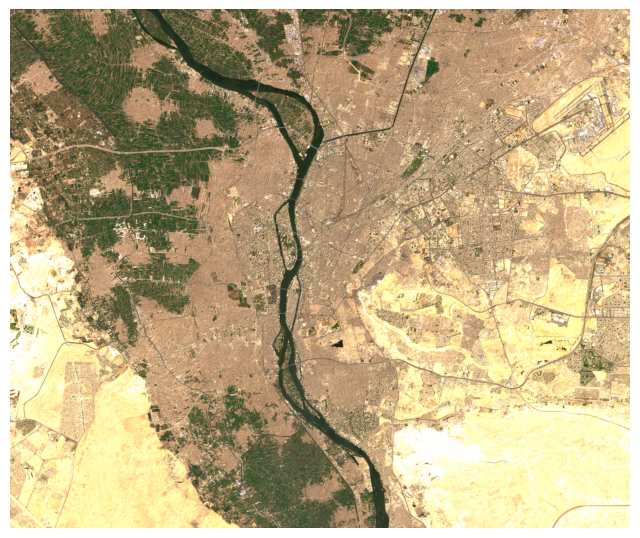

In [162]:
bbox_crop = [31.059723,29.906937,31.425018,30.171310]

bandes = []
for nom in ["B04", "B03", "B02"]:   # rouge, vert, bleu
    with rasterio.open(selected_item.assets[nom].href) as src:
        b = transform_bounds("EPSG:4326", src.crs, *bbox_crop)   # bbox lon/lat → CRS de l'image
        fenetre = from_bounds(*b, transform=src.transform)  # zone à lire, en pixels
        bandes.append(src.read(1, window=fenetre))

rgb = np.dstack(bandes).astype("float32") / 10000   # 2020 : pas de -1000
plt.figure(figsize=(8, 8))
plt.imshow(np.clip(rgb * 3.5, 0, 1))   # *3.5 éclaircit l'image
plt.axis("off")